# 02 — Data Understanding (CRISP-DM)

Explora a **base bruta canônica** (`dataset_cafeterias_rj.parquet`), validando esquema,
regras de negócio e distribuições. Nada é alterado aqui: apenas diagnóstico.


## Carregamento e esquema

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.data.preparar_dataset import carregar_dados_brutos, validar_esquema

df = carregar_dados_brutos()
print(f"Grão: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

Grão: 35,088 linhas x 38 colunas


,data,loja,produto,categoria,custo_producao,preco_original,desconto_pct,preco_final,quantidade_vendida_dia,dia_semana,...,estoque_disponivel,ruptura_flag,lead_time_reposicao,temperatura,chuva_mm,custo_logistico,custo_marketing_unitario,preco_minimo,margem_minima,quantidade_vendida_mes
0,2024-01-01,Unidade A,Docinho de Festa (cento),Doce,68.87,240.0,0.1102,213.55,1,Monday,...,1,0,5,28.0,1.0,5.40,1017.82,86.23,0.252,34
1,2024-01-01,Unidade A,"Empadao Congelado 1,2 kg",Salgado,38.19,98.0,0.0000,98.00,1,Monday,...,1,0,1,28.0,1.0,5.86,905.33,53.39,0.398,31
2,2024-01-01,Unidade A,Fatia de Torta,Torta,8.19,24.0,0.0000,24.00,6,Monday,...,9,0,1,28.0,1.0,6.60,197.07,11.05,0.349,270
3,2024-01-01,Unidade A,Kit Docura 3,Kit,133.82,389.0,0.0000,389.00,0,Monday,...,1,0,1,28.0,1.0,8.94,576.86,182.00,0.360,9
4,2024-01-01,Unidade A,Kit Festa 2,Kit,133.09,379.0,0.0000,379.00,1,Monday,...,1,0,2,28.0,1.0,6.03,1084.91,173.02,0.300,26


In [2]:
df.dtypes.to_frame('tipo')

,tipo
data,datetime64[ns]
loja,object
produto,object
categoria,object
custo_producao,float64
preco_original,float64
desconto_pct,float64
preco_final,float64
quantidade_vendida_dia,int64
dia_semana,object


## Relatório de qualidade (fail-closed)

A mesma validação usada no pipeline é aplicada aqui, para que o notebook mostre o
estado real da base.

In [3]:
problemas = validar_esquema(df)
print("Base íntegra: nenhum problema encontrado." if not problemas else "\n".join(problemas))

Base íntegra: nenhum problema encontrado.


## Estatísticas descritivas das variáveis-chave

In [4]:
colunas = [
    "preco_original", "desconto_pct", "preco_final",
    "custo_producao", "quantidade_vendida_dia", "preco_competidor",
]
df[colunas].describe().round(2)

,preco_original,desconto_pct,preco_final,custo_producao,quantidade_vendida_dia,preco_competidor
count,35088.00,35088.00,35088.00,35088.00,35088.00,35088.00
mean,245.79,0.02,241.42,93.08,1.70,253.13
std,140.93,0.05,140.74,54.74,2.41,146.57
min,24.00,0.00,12.00,7.75,0.00,21.60
25%,136.50,0.00,129.00,53.49,1.00,137.74
50%,229.50,0.00,219.00,83.18,1.00,234.93
75%,369.00,0.00,369.00,133.83,2.00,362.98
max,519.00,0.50,519.00,228.88,63.00,601.97


## Receita por categoria e por unidade

In [5]:
df["receita_dia"] = df["preco_final"] * df["quantidade_vendida_dia"]
df.groupby("categoria")["receita_dia"].sum().round(2).sort_values(ascending=False)

categoria
Torta      5796252.13
Salgado     814269.34
Kit         612662.10
Doce        395535.96
Name: receita_dia, dtype: float64

In [6]:
df.groupby("loja")["receita_dia"].sum().round(2)

loja
Unidade A    4481067.13
Unidade B    3137652.40
Name: receita_dia, dtype: float64

## Sazonalidade: receita mensal

O pico de fim de ano (Q4) é o cenário mais adverso — e será justamente o **teste**
do split temporal na próxima etapa.

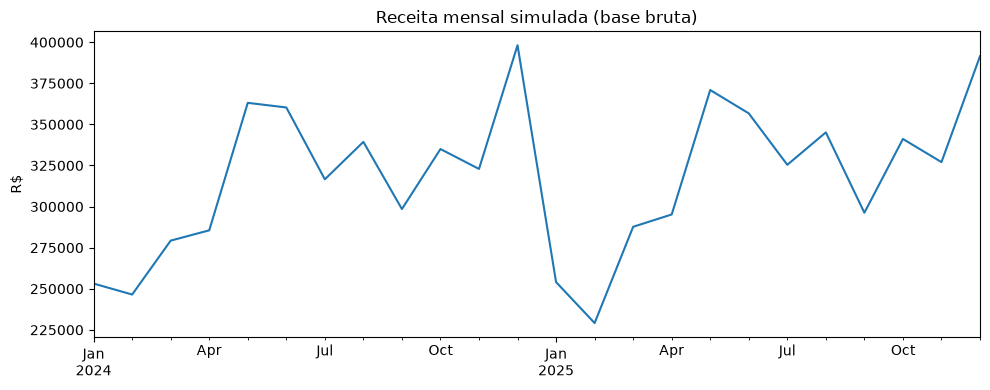

In [7]:
mensal = df.groupby(pd.Grouper(key="data", freq="MS"))["receita_dia"].sum()
ax = mensal.plot(figsize=(10, 4), title="Receita mensal simulada (base bruta)")
ax.set_ylabel("R$")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Achados

- A base é **coerente por construção**: preço final reconstruível a partir de
  preço original e desconto.
- Há **sazonalidade marcada** (festas de fim de ano) e **diferença entre unidades**.
- Existe uma coluna de **agregado mensal** que precisa ser tratada como vazamento
  na etapa de preparação.
